Celem przykładu jest prezentacja podstawowych możliwości pracy na obrazach cyfrowych, przy wykorzystaniu biblioteki OpenCV : ładowanie i wyświetlanie obrazu; filtracja prostym filtrem uśredniającym

In [1]:
import cv2
import numpy as np

from PIL import Image

In [13]:
img = cv2.imread('kotek.jpg', cv2.IMREAD_COLOR)

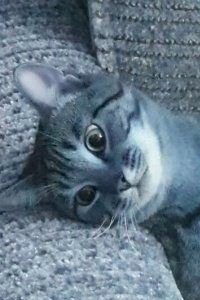

In [14]:
img = img[0:300, 0:200, :]
Image.fromarray(img)

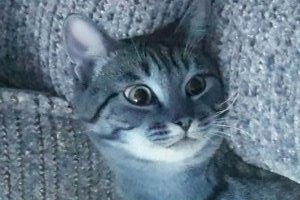

In [15]:
img = img.transpose((1,0,2))
Image.fromarray(img)

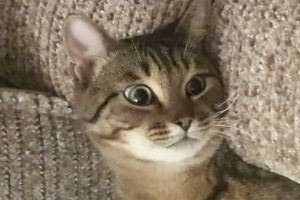

In [16]:

# oryginalny zapis składowych obrazu to BGR, do prezentacji należy odwrócić do RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# do wyświetlania korzystamy z PIL.Image (zamiast cv2.imshow, które nie jest przeznaczone do użycia w Jupyterze)
Image.fromarray(img)

In [19]:
img = cv2.imread('kotek.jpg', cv2.IMREAD_COLOR)

Dokumentacja użytej w przykładzie funkcji filtrującej: https://docs.opencv.org/4.5.3/d4/d86/group__imgproc__filter.html#ga27c049795ce870216ddfb366086b5a04

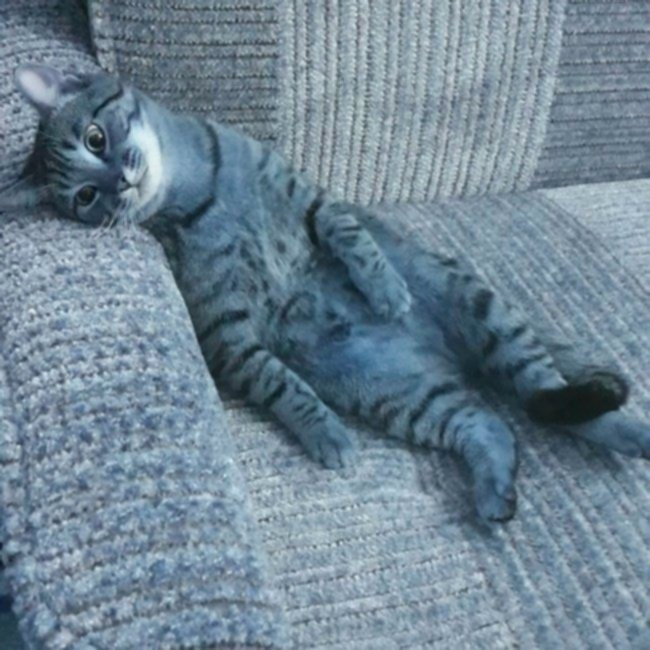

In [20]:
# maska filtru jako macierz 3x3 samych jedynek, wartość norm. = 9
kernel_blur = np.ones((3, 3), np.float32) / 9

# filtracja przy wykorzystaniu odpowiedniej metody biblioteki OpenCV
Output_image1 = cv2.filter2D(src=img, ddepth=-1, kernel=kernel_blur)

Image.fromarray(Output_image1)

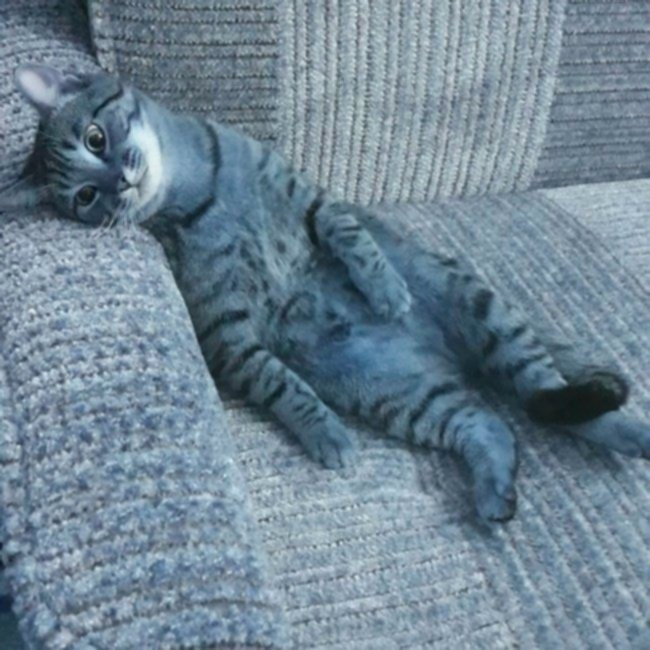

In [21]:
# bezpośrednie utworzenie macierzy (maski filtru) – możliwość wprowadzania różnych wartości
kernel_blur_matrix = np.array([[1, 1, 1], 
                               [1, 1, 1], 
                               [1, 1, 1]])/9  # dlaczego dzielimy przez 9? chcemy sume 1?

Output_image2 = cv2.filter2D(src=img, ddepth=-1, kernel=kernel_blur_matrix)

Image.fromarray(Output_image2)

Bo wtedy filtr nie zmienia jasności obrazu, tylko jego szczegóły (np. rozmywa, wygładza).

Wynik to suma ważona pikseli, więc jeśli wagi sumują się do 1, to w jednolitym obszarze (wszystkie piksele np. 100) wynik też wynosi 100. Gdyby suma wynosiła 9, dostalibyśmy 900, czyli obraz byłby 9 razy jaśniejszy (i obcięty do 255). Gdyby suma wynosiła 0,5, obraz byłby dwa razy ciemniejszy.